# Network Threat Detection on CSE-CIC-IDS2018 — From Data Audit to a Working Demo

**Academic team project (IoT security course) — notebook and application by Fils Aboubakar Sidik MBOHOU**

Can a model separate **benign** network flows from **attack** flows reliably enough to be useful, and can it be served exactly the way it was evaluated?

The notebook follows the project step by step:

1. audit the data before trusting any score (duplicates, contradictory labels, constant columns);
2. split into training, validation and test sets with no flow shared between them;
3. compare three model families under the same rules;
4. choose the model and the decision threshold on validation only;
5. evaluate once on the test set and analyse where the errors come from;
6. export one artifact that the demo application loads as is.

## 1. Environment and reproducibility

All random steps use the same seed. Library versions are printed so the run can be compared with another environment.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")

import json
import platform
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)

SEED = 42
np.random.seed(SEED)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
ART_DIR = Path("artifacts")
ART_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("Python      ", platform.python_version())
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.12.3
pandas       3.0.2
numpy        2.4.4
scikit-learn 1.8.0


## 2. Load the data

The file is the course sample of CSE-CIC-IDS2018 (Canadian Institute for Cybersecurity / University of New Brunswick). Each row is one **network flow** described by 72 statistics computed by CICFlowMeter (packet counts and sizes, inter-arrival times, TCP flags, idle/active times), plus a `Label`.

The first column is a saved pandas index, so I drop it.

In [2]:
DATA_PATH = Path("3_CSE-CIC-IDS2018.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place 3_CSE-CIC-IDS2018.csv in the same folder as this notebook.")

raw = pd.read_csv(DATA_PATH)
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]

print("Raw shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print()
print(raw["Label"].value_counts().to_string())

Raw shape: (246730, 73)
Missing values: 0

Label
Benign                      75000
Infilteration               40000
Bot                         20000
DoS attacks-Hulk            20000
DoS attacks-SlowHTTPTest    20000
FTP-BruteForce              15000
SSH-Bruteforce              15000
DoS attacks-GoldenEye       15000
DDOS attack-HOIC            15000
DoS attacks-Slowloris       10000
DDOS attack-LOIC-UDP         1730


The class counts are round numbers (75,000 / 40,000 / 20,000 / 15,000 …). This sample was **built per class**, so about 70% of the rows are attacks. Real traffic is overwhelmingly benign, so accuracy on this sample says little about a real alert rate. I keep this in mind when choosing metrics.

Ten attack labels are present: brute force (FTP, SSH), DoS (Hulk, GoldenEye, Slowloris, SlowHTTPTest), DDoS (HOIC, LOIC-UDP), botnet traffic (Bot) and **Infilteration** (the dataset's spelling).

## 3. Data audit

Before modelling I check four things: columns that never vary, impossible values, exact duplicates and identical flows carrying different labels.

In [3]:
features_all = [c for c in raw.columns if c != "Label"]
constant_cols = [c for c in features_all if raw[c].nunique() <= 1]
print("Constant columns:", len(constant_cols), constant_cols)

neg_duration = int((raw["Flow Duration"] < 0).sum())
print("Rows with a negative flow duration:", neg_duration)
print("Rows with Init Bwd Win Byts = -1 (window not observed):", int((raw["Init Bwd Win Byts"] == -1).sum()))

dup_rows = int(raw.duplicated().sum())
print(f"Exact duplicate rows: {dup_rows:,} ({dup_rows / len(raw):.1%})")

features = [c for c in features_all if c not in constant_cols]
dedup = raw.drop_duplicates()
n_lab = dedup.groupby(features)["Label"].transform("nunique")
conflicts = dedup[n_lab > 1]
print(f"After removing exact duplicates, {len(conflicts):,} rows share an identical feature vector "
      f"with a different label ({conflicts.groupby(features).ngroups:,} distinct vectors).")

Constant columns: 8 ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']
Rows with a negative flow duration: 1
Rows with Init Bwd Win Byts = -1 (window not observed): 97017


Exact duplicate rows: 66,935 (27.1%)


After removing exact duplicates, 3,036 rows share an identical feature vector with a different label (1,517 distinct vectors).


**Cleaning decisions**

- drop the 8 constant columns (they carry no information);
- drop the single row with a negative duration (a measurement error);
- keep `Init Bwd Win Byts = -1` as is: it is a sentinel meaning "not observed", which tree models handle naturally;
- remove exact duplicates;
- remove flows whose identical feature vector appears under different labels: the model cannot learn a correct answer for them, and they would blur the evaluation.

In [4]:
df = raw.drop(columns=constant_cols)
df = df[df["Flow Duration"] >= 0]
df = df.drop_duplicates()
n_labels = df.groupby(features)["Label"].transform("nunique")
conflict_rows = int((n_labels > 1).sum())
df = df[n_labels == 1].reset_index(drop=True)

audit = {
    "raw_rows": len(raw),
    "constant_columns_removed": len(constant_cols),
    "negative_duration_rows_removed": neg_duration,
    "exact_duplicates_removed": dup_rows,
    "conflicting_label_rows_removed": conflict_rows,
    "clean_rows": len(df),
    "features": len(features),
}
print(json.dumps(audit, indent=1))
print()
print(df["Label"].value_counts().to_string())

{
 "raw_rows": 246730,
 "constant_columns_removed": 8,
 "negative_duration_rows_removed": 1,
 "exact_duplicates_removed": 66935,
 "conflicting_label_rows_removed": 3036,
 "clean_rows": 176758,
 "features": 64
}

Label
Benign                      70946
Infilteration               35472
DoS attacks-Hulk            15262
DoS attacks-GoldenEye       14980
DDOS attack-HOIC            11427
Bot                         10475
DoS attacks-Slowloris        9047
SSH-Bruteforce               7348
DDOS attack-LOIC-UDP         1730
DoS attacks-SlowHTTPTest       40
FTP-BruteForce                 31


The duplicates are not spread evenly. Some attack families are almost entirely made of the same few flows repeated thousands of times. The chart compares the rows in the sample with the distinct flows kept after cleaning:

                           rows  distinct flows kept  kept share
Label                                                           
Benign                    75000                70946       0.946
Infilteration             40000                35472       0.887
Bot                       20000                10475       0.524
DoS attacks-Hulk          20000                15262       0.763
DoS attacks-SlowHTTPTest  20000                   40       0.002
DDOS attack-HOIC          15000                11427       0.762
DoS attacks-GoldenEye     15000                14980       0.999
SSH-Bruteforce            15000                 7348       0.490
FTP-BruteForce            15000                   31       0.002
DoS attacks-Slowloris     10000                 9047       0.905
DDOS attack-LOIC-UDP       1730                 1730       1.000


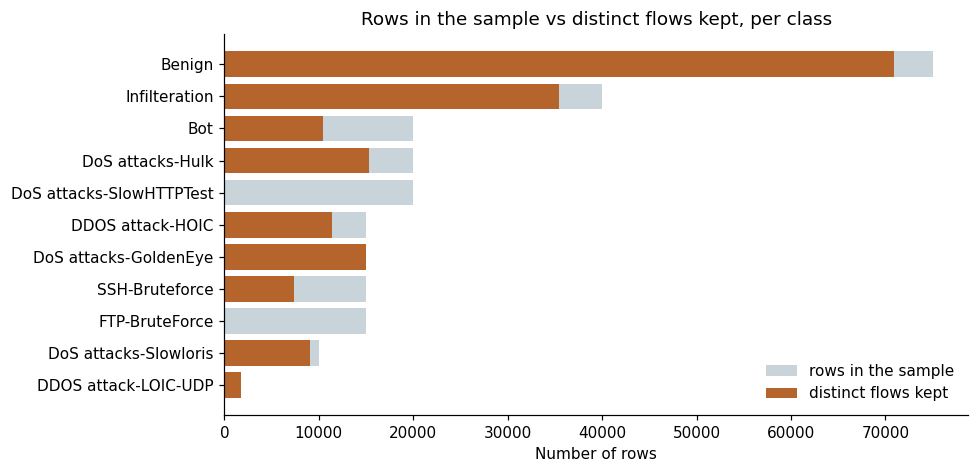

In [5]:
per_class = pd.DataFrame({
    "rows": raw["Label"].value_counts(),
    "distinct flows kept": df["Label"].value_counts(),
}).sort_values("rows", ascending=False)
per_class["kept share"] = (per_class["distinct flows kept"] / per_class["rows"]).round(3)
print(per_class.to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
y_pos = np.arange(len(per_class))
ax.barh(y_pos, per_class["rows"], color="#c9d3da", label="rows in the sample")
ax.barh(y_pos, per_class["distinct flows kept"], color="#b5652b", label="distinct flows kept")
ax.set_yticks(y_pos, per_class.index)
ax.invert_yaxis()
ax.set_xlabel("Number of rows")
ax.set_title("Rows in the sample vs distinct flows kept, per class")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-duplicates-by-class.png", dpi=110)
plt.show()

FTP-BruteForce has 15,000 rows but only 31 distinct flows left after cleaning; SlowHTTPTest has 20,000 rows but 40. With a random split on the raw sample, the same flow lands in both training and test sets, so a "100% detection" on these classes mostly measures memorisation.

### Benign and Infiltration look alike

Most attack families target a single service: port 80 for DoS/DDoS, 21 for FTP brute force, 22 for SSH, 8080 for the botnet. Infiltration is different. Its flows use the same destinations as normal traffic (DNS on 53, HTTPS on 443, RDP on 3389).

This matches published criticism of the dataset. Liu, Engelen et al. (IEEE CNS 2022) report labelling and attack-orchestration errors in CIC-IDS-2017 and CSE-CIC-IDS-2018. I therefore treat Infiltration as the class where the labels themselves are least reliable.

port           53 (DNS)  443 (HTTPS)  3389 (RDP)  80 (HTTP)  other
Label                                                             
Benign             22.4         11.8        10.3        8.1   47.4
Infilteration      31.3         19.4         9.4        3.4   36.5


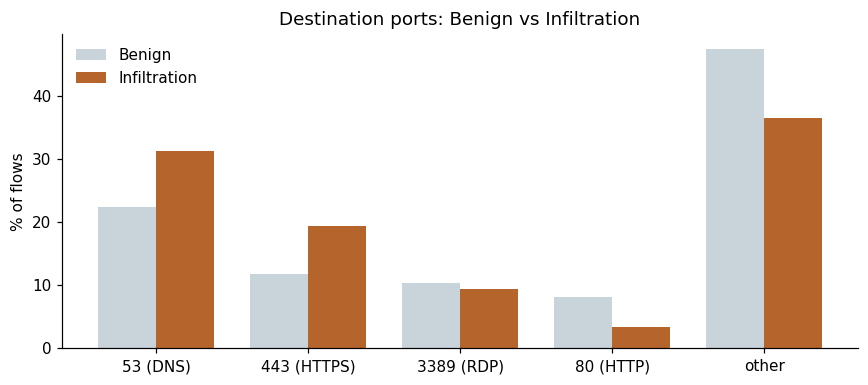

In [6]:
ports = [53, 443, 3389, 80]
share = (
    df[df["Label"].isin(["Benign", "Infilteration"])]
    .assign(port=lambda d: d["Dst Port"].where(d["Dst Port"].isin(ports), other=-1))
    .groupby("Label")["port"].value_counts(normalize=True)
    .unstack(fill_value=0)
)
share = share.rename(columns={-1: "other", 53: "53 (DNS)", 443: "443 (HTTPS)", 3389: "3389 (RDP)", 80: "80 (HTTP)"})
share = share[["53 (DNS)", "443 (HTTPS)", "3389 (RDP)", "80 (HTTP)", "other"]]
print((share * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(share.shape[1])
w = 0.38
ax.bar(x - w / 2, share.loc["Benign"] * 100, w, color="#c9d3da", label="Benign")
ax.bar(x + w / 2, share.loc["Infilteration"] * 100, w, color="#b5652b", label="Infiltration")
ax.set_xticks(x, share.columns)
ax.set_ylabel("% of flows")
ax.set_title("Destination ports: Benign vs Infiltration")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-benign-vs-infiltration-ports.png", dpi=110)
plt.show()

## 4. Target and split

The task is **binary detection**, 0 = benign, 1 = attack. I keep the attack family on the side, only for stratification and error analysis.

I split **after** cleaning: 70% training, 15% validation, 15% test, stratified by attack family. The validation set chooses the model and the decision threshold. The test set is used once, at the end.

In [7]:
X = df[features]
y = (df["Label"] != "Benign").astype(int).to_numpy()
family = df["Label"].to_numpy()

X_train, X_tmp, y_train, y_tmp, fam_train, fam_tmp = train_test_split(
    X, y, family, test_size=0.30, stratify=family, random_state=SEED)
X_val, X_test, y_val, y_test, fam_val, fam_test = train_test_split(
    X_tmp, y_tmp, fam_tmp, test_size=0.50, stratify=fam_tmp, random_state=SEED)

for name, part, yy in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<11}{len(part):>8,} rows   attack share {yy.mean():.1%}")

# Guard against leakage: no feature vector may appear in two splits.
key = lambda d: set(pd.util.hash_pandas_object(d, index=False))
print("Shared feature vectors train/test:", len(key(X_train) & key(X_test)))
print("Shared feature vectors train/val :", len(key(X_train) & key(X_val)))

train       123,730 rows   attack share 59.9%
validation   26,514 rows   attack share 59.9%
test         26,514 rows   attack share 59.9%
Shared feature vectors train/test: 0
Shared feature vectors train/val : 0


## 5. Metrics

Accuracy depends on the attack share, which this sample fixed artificially at about 70%. I therefore compare models on:

- **Macro F1** (main metric): benign and attack count equally;
- **detection rate** (recall on attacks) and **false-alarm rate** (benign flows flagged as attacks), the two numbers a security team actually lives with;
- **ROC-AUC** and **PR-AUC**, which do not depend on a single threshold.

In [8]:
def scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "detection_rate": recall_score(y_true, pred),
        "false_alarm_rate": 1 - recall_score(y_true, pred, pos_label=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }

## 6. Three model families

I compare a linear model and two tree ensembles, trained under the same rules:

- **Logistic Regression**: a linear baseline. Flow statistics are extremely skewed (durations range from microseconds to two minutes), so I apply a signed log transform, then standardise. Both steps live inside the pipeline and are fitted on training data only.
- **Random Forest**: a strong, widely used baseline for tabular data.
- **Gradient boosting**: I use `HistGradientBoostingClassifier`, scikit-learn's histogram-based implementation. It is much faster than the classic `GradientBoostingClassifier` on 120k rows and handles skewed features without scaling. Its early stopping uses an internal slice of the training set, never the validation set.

In [9]:
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")

candidates = {
    "Logistic Regression": make_pipeline(signed_log, StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=400, early_stopping=True, validation_fraction=0.1, random_state=SEED),
}

val_rows = []
fitted = {}
for name, model in candidates.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    val_rows.append({"model": name, **scores(y_val, model.predict_proba(X_val)[:, 1])})

val_table = pd.DataFrame(val_rows).set_index("model")
print("Validation results at the default 0.5 threshold")
print(val_table.round(4).to_string())

Validation results at the default 0.5 threshold
                     accuracy  macro_f1  balanced_acc  detection_rate  false_alarm_rate  roc_auc  pr_auc
model                                                                                                   
Logistic Regression    0.8084    0.8041        0.8110          0.7978            0.1759   0.8916  0.9274
Random Forest          0.8512    0.8456        0.8466          0.8703            0.1771   0.9462  0.9665
Gradient Boosting      0.8836    0.8786        0.8777          0.9076            0.1523   0.9646  0.9770


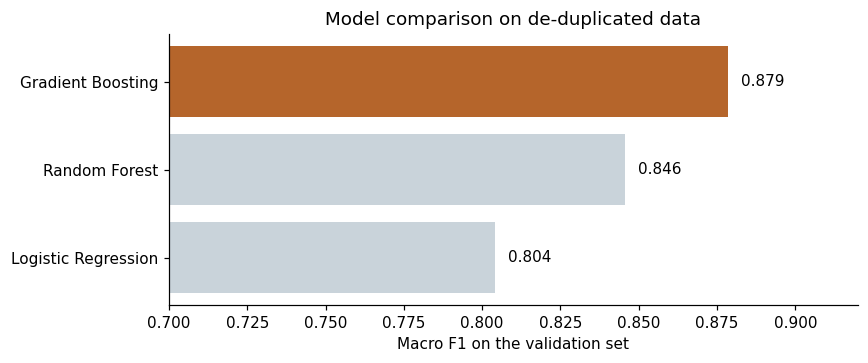

In [10]:
order = val_table["macro_f1"].sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(order, val_table.loc[order, "macro_f1"], color=["#c9d3da", "#c9d3da", "#b5652b"])
for i, v in enumerate(val_table.loc[order, "macro_f1"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center")
ax.set_xlim(0.7, 0.92)
ax.set_xlabel("Macro F1 on the validation set")
ax.set_title("Model comparison on de-duplicated data")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-model-comparison.png", dpi=110)
plt.show()

Gradient boosting is ahead on every metric, including the false-alarm rate. Logistic Regression is clearly behind: the boundary between benign and attack traffic is not linear in these features.

I keep gradient boosting.

## 7. Light tuning on validation

I try a small grid of settings that control how complex each tree can be. The grid is deliberately small: the aim is to check that the default is reasonable, not to squeeze the last decimal out of the validation set.

In [11]:
grid = [
    {"learning_rate": 0.1, "max_leaf_nodes": 31, "l2_regularization": 0.0},
    {"learning_rate": 0.1, "max_leaf_nodes": 63, "l2_regularization": 0.0},
    {"learning_rate": 0.05, "max_leaf_nodes": 63, "l2_regularization": 1.0},
    {"learning_rate": 0.05, "max_leaf_nodes": 127, "l2_regularization": 1.0},
]
tuning = []
for params in grid:
    m = HistGradientBoostingClassifier(max_iter=600, early_stopping=True, validation_fraction=0.1,
                                       random_state=SEED, **params).fit(X_train, y_train)
    s = scores(y_val, m.predict_proba(X_val)[:, 1])
    tuning.append({**params, "iterations": m.n_iter_, "macro_f1": s["macro_f1"], "pr_auc": s["pr_auc"]})
    fitted[str(params)] = m

tuning = pd.DataFrame(tuning)
print(tuning.round(4).to_string(index=False))
best_params = grid[int(tuning["macro_f1"].idxmax())]
best_model = fitted[str(best_params)]
print("\nSelected:", best_params)

 learning_rate  max_leaf_nodes  l2_regularization  iterations  macro_f1  pr_auc
          0.10              31                0.0         377    0.8786  0.9770
          0.10              63                0.0         236    0.8772  0.9769
          0.05              63                1.0         464    0.8778  0.9770
          0.05             127                1.0         228    0.8794  0.9771

Selected: {'learning_rate': 0.05, 'max_leaf_nodes': 127, 'l2_regularization': 1.0}


## 8. Choosing the decision threshold

A probability of 0.5 is not sacred. I scan thresholds **on the validation set only** and keep the one that maximises Macro F1. The curve also shows the trade-off a SOC would actually tune: fewer false alarms means more missed attacks.

Chosen threshold: 0.48
 threshold  macro_f1  detection_rate  false_alarm_rate
      0.30    0.8543          0.9828            0.3028
      0.48    0.8805          0.9170            0.1605
      0.50    0.8794          0.9067            0.1490
      0.70    0.8526          0.7844            0.0430


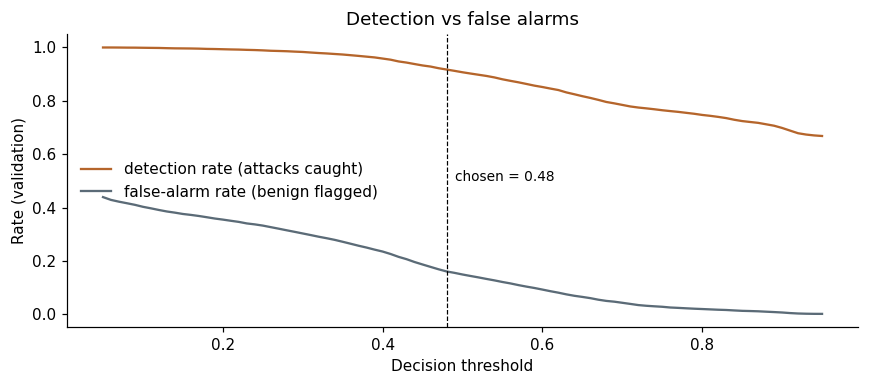

In [12]:
p_val = best_model.predict_proba(X_val)[:, 1]
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame([{"threshold": t, **scores(y_val, p_val, t)} for t in thresholds])
THRESHOLD = float(curve.loc[curve["macro_f1"].idxmax(), "threshold"])
print("Chosen threshold:", THRESHOLD)
print(curve[curve["threshold"].isin([0.3, 0.5, THRESHOLD, 0.7])][["threshold", "macro_f1", "detection_rate", "false_alarm_rate"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curve["threshold"], curve["detection_rate"], color="#b5652b", label="detection rate (attacks caught)")
ax.plot(curve["threshold"], curve["false_alarm_rate"], color="#5b6b77", label="false-alarm rate (benign flagged)")
ax.axvline(THRESHOLD, color="black", lw=0.8, ls="--")
ax.text(THRESHOLD + 0.01, 0.5, f"chosen = {THRESHOLD:.2f}", fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate (validation)")
ax.set_title("Detection vs false alarms")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-threshold-tradeoff.png", dpi=110)
plt.show()

## 9. Diagnostics on validation

Two questions before touching the test set:

1. **Does the model just read the destination port?** Many attack families use one fixed port, so the model could memorise ports instead of behaviour. I retrain without `Dst Port`.
2. **Where do the errors come from?** I measure how well the model separates Benign from Infiltration alone, and how it performs once Infiltration is set aside.

In [13]:
no_port = [f for f in features if f != "Dst Port"]
m_np = HistGradientBoostingClassifier(max_iter=600, early_stopping=True, validation_fraction=0.1,
                                      random_state=SEED, **best_params).fit(X_train[no_port], y_train)
s_full = scores(y_val, p_val, THRESHOLD)
s_np = scores(y_val, m_np.predict_proba(X_val[no_port])[:, 1], THRESHOLD)

bi = np.isin(fam_val, ["Benign", "Infilteration"])
no_inf = fam_val != "Infilteration"
diag = pd.DataFrame({
    "all features": s_full,
    "without Dst Port": s_np,
}).T[["macro_f1", "detection_rate", "false_alarm_rate", "roc_auc"]]
print(diag.round(4).to_string())
print()
print(f"ROC-AUC, Benign vs Infiltration only : {roc_auc_score(y_val[bi], p_val[bi]):.3f}")
print(f"Macro F1 with Infiltration set aside : {f1_score(y_val[no_inf], (p_val[no_inf] >= THRESHOLD).astype(int), average='macro'):.4f}")

                  macro_f1  detection_rate  false_alarm_rate  roc_auc
all features        0.8805          0.9170            0.1605   0.9648
without Dst Port    0.8733          0.9071            0.1635   0.9614

ROC-AUC, Benign vs Infiltration only : 0.895
Macro F1 with Infiltration set aside : 0.9188


Removing the port costs a little, but performance stays close: the model relies mostly on how flows behave, not only on where they go.

The second result locates the problem. Setting Infiltration aside raises Macro F1 from 0.88 to 0.92. What remains is mostly benign flows flagged because they resemble Infiltration: the threshold was chosen with Infiltration present. Separating Benign from Infiltration alone reaches a ROC-AUC of only about 0.90, far below the other families. The audit already showed why: the two classes look alike.

## 10. Final evaluation on the test set (run once)

{
 "accuracy": 0.8826,
 "macro_f1": 0.8769,
 "balanced_acc": 0.8744,
 "detection_rate": 0.9161,
 "false_alarm_rate": 0.1674,
 "roc_auc": 0.9641,
 "pr_auc": 0.9766
}
Confusion matrix [[TN, FP], [FN, TP]]: [[8861, 1781], [1332, 14540]]
Attack precision: 0.8909


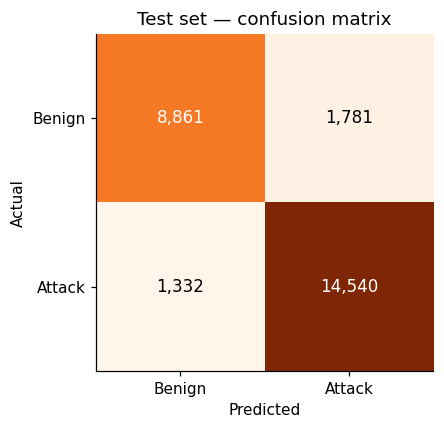

In [14]:
p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)
test_scores = scores(y_test, p_test, THRESHOLD)
cm = confusion_matrix(y_test, pred_test)
print(json.dumps({k: round(v, 4) for k, v in test_scores.items()}, indent=1))
print("Confusion matrix [[TN, FP], [FN, TP]]:", cm.tolist())
print(f"Attack precision: {precision_score(y_test, pred_test):.4f}")

fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(cm, cmap="Oranges")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], ["Benign", "Attack"])
ax.set_yticks([0, 1], ["Benign", "Attack"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Test set — confusion matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-test-confusion.png", dpi=110)
plt.show()

                          correctly classified  test flows
family                                                    
Infilteration                           0.7499        5321
Benign                                  0.8326       10642
DDOS attack-HOIC                        0.9994        1714
Bot                                     1.0000        1572
DoS attacks-GoldenEye                   1.0000        2247
DoS attacks-Hulk                        1.0000        2290
DoS attacks-SlowHTTPTest                1.0000           6
DDOS attack-LOIC-UDP                    1.0000         259
DoS attacks-Slowloris                   1.0000        1357
FTP-BruteForce                          1.0000           4
SSH-Bruteforce                          1.0000        1102


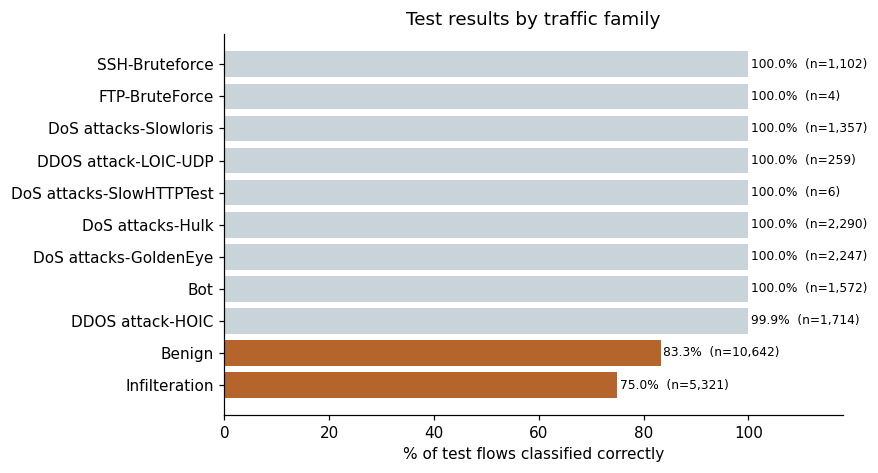

In [15]:
by_family = (
    pd.DataFrame({"family": fam_test, "correct": pred_test == y_test})
    .groupby("family")["correct"].agg(["mean", "size"])
    .rename(columns={"mean": "correctly classified", "size": "test flows"})
    .sort_values("correctly classified")
)
print(by_family.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4.4))
colors = ["#b5652b" if f in ("Infilteration", "Benign") else "#c9d3da" for f in by_family.index]
ax.barh(by_family.index, by_family["correctly classified"] * 100, color=colors)
for i, (v, n) in enumerate(zip(by_family["correctly classified"], by_family["test flows"])):
    ax.text(min(v * 100 + 0.5, 101), i, f"{v:.1%}  (n={n:,})", va="center", fontsize=8)
ax.set_xlim(0, 118)
ax.set_xlabel("% of test flows classified correctly")
ax.set_title("Test results by traffic family")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-test-by-family.png", dpi=110)
plt.show()

Families with a very small test count (FTP-BruteForce, SlowHTTPTest) only have a handful of distinct flows after de-duplication, so their 100% should be read as "no error on a few examples", not as a robust estimate.

## 11. What the model relies on

Gradient boosting has no built-in impurity importance, so I use **permutation importance on the validation set**: shuffle one feature, measure how much Macro F1 drops. This describes the model's behaviour; it is not a causal statement about attacks.

Fwd Seg Size Min    0.1627
Dst Port            0.0749
ECE Flag Cnt        0.0295
Pkt Len Std         0.0235
Pkt Len Var         0.0225
Bwd Pkt Len Std     0.0193
Fwd Pkt Len Std     0.0157
Fwd Pkts/s          0.0135
Fwd Pkt Len Max     0.0117
Bwd Seg Size Avg    0.0105


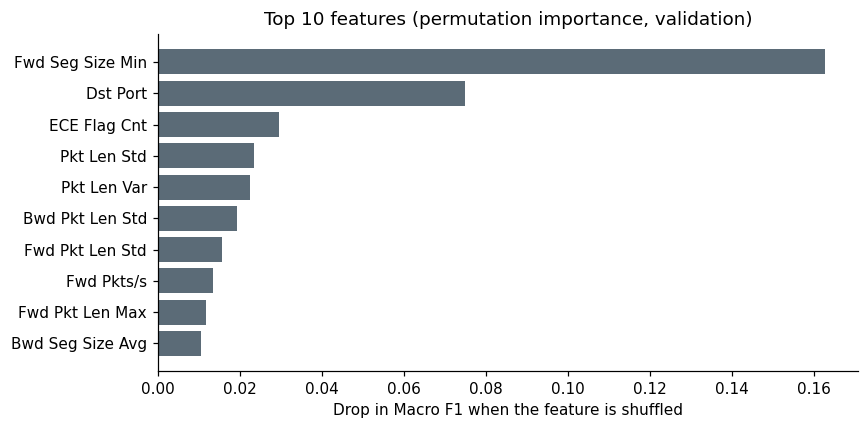

In [16]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_val), size=min(8000, len(X_val)), replace=False)
macro_f1_at_threshold = lambda est, Xs, ys: f1_score(ys, (est.predict_proba(Xs)[:, 1] >= THRESHOLD).astype(int), average="macro")
pi = permutation_importance(best_model, X_val.iloc[idx], y_val[idx], scoring=macro_f1_at_threshold,
                            n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=features).sort_values(ascending=False).head(10)
print(imp.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color="#5b6b77")
ax.set_xlabel("Drop in Macro F1 when the feature is shuffled")
ax.set_title("Top 10 features (permutation importance, validation)")
plt.tight_layout()
plt.savefig(FIG_DIR / "iot-permutation-importance.png", dpi=110)
plt.show()

## 12. Deployment artifact

A frequent failure in deployed machine learning is **train/serve skew**: the application prepares the data differently from the notebook, and the model silently returns wrong answers. To rule it out by design, everything needed to score a flow travels in **one file**: the fitted model, the exact ordered feature list, the decision threshold and the library version. The application loads that file and selects columns **by name**, so a reordered or incomplete CSV is rejected instead of being mis-scored.

Gradient boosting does not need scaling, so there is no separate preprocessing object to forget.

In [17]:
artifact = {
    "model": best_model,
    "features": features,
    "threshold": THRESHOLD,
    "positive_label": "Attack",
    "negative_label": "Benign",
    "trained_on": "CSE-CIC-IDS2018 course sample, de-duplicated, 70% training split",
    "sklearn_version": sklearn.__version__,
    "test_scores": {k: round(v, 4) for k, v in test_scores.items()},
}
joblib.dump(artifact, ART_DIR / "threat_detector.joblib", compress=3)
(ART_DIR / "feature_schema.json").write_text(json.dumps({"features": features, "threshold": THRESHOLD}, indent=1))

# A small demo file of real test flows (with their true label, which the app uses for comparison).
demo = X_test.copy()
demo["Label"] = fam_test
demo_sample = pd.concat([g.sample(min(len(g), 4), random_state=SEED) for _, g in demo.groupby("Label")])
demo_sample.sample(frac=1, random_state=SEED).to_csv(ART_DIR / "demo_flows.csv", index=False)

print("Demo file:", demo_sample.shape, "labels kept:", "Label" in demo_sample.columns)
print("Saved:", sorted(p.name for p in ART_DIR.iterdir()))
print(f"Model file size: {(ART_DIR / 'threat_detector.joblib').stat().st_size / 1e6:.1f} MB")

summary = {"audit": audit, "split": [len(X_train), len(X_val), len(X_test)],
           "validation": val_table.round(4).to_dict(orient="index"),
           "selected_params": best_params, "threshold": THRESHOLD,
           "test": {k: round(v, 4) for k, v in test_scores.items()}, "test_confusion": cm.tolist(),
           "test_by_family": by_family["correctly classified"].round(4).to_dict(),
           "diagnostics": diag.round(4).to_dict(orient="index")}
(ART_DIR / "results_summary.json").write_text(json.dumps(summary, indent=1, default=str))

Demo file: (44, 65) labels kept: True
Saved: ['demo_flows.csv', 'feature_schema.json', 'threat_detector.joblib']
Model file size: 1.5 MB


1893

### Check: the saved artifact scores exactly like the evaluated model

I reload the file from disk, as the application does, shuffle the column order of the test set, and compare the predictions with the ones evaluated above.

In [18]:
served = joblib.load(ART_DIR / "threat_detector.joblib")
shuffled = X_test[X_test.columns[::-1]]                       # columns in a different order
p_served = served["model"].predict_proba(shuffled[served["features"]])[:, 1]
pred_served = (p_served >= served["threshold"]).astype(int)

print("Max probability difference:", float(np.abs(p_served - p_test).max()))
print("Identical verdicts on the test set:", bool((pred_served == pred_test).all()), f"({len(pred_served):,} flows)")

Max probability difference: 0.0
Identical verdicts on the test set: True (26,514 flows)


## 13. Conclusions

- On de-duplicated data, with model and threshold chosen on validation and a single test run, **gradient boosting** is the best of the three families.
- Almost every error is a confusion between **Benign and Infiltration**. Those two classes share the same ports and similar flow statistics, and the dataset's labelling of Infiltration has been criticised in the literature. The other attack families are detected almost perfectly, but several contain very few distinct flows.
- Performance holds without the destination port, so the model is not just a port lookup table.
- The deployment artifact bundles model, feature order and threshold; reloaded from disk it reproduces the test verdicts exactly, so the demo application cannot score a flow with the wrong preprocessing.

**Limits.** This is a class-balanced sample of one public lab dataset, not live traffic. The attack share (about 70%) is far from reality, so precision and alert volume in production would differ. Labels for Infiltration are questionable. Flow statistics only exist once a flow is finished, so this is not a packet-level real-time detector. The dataset is general enterprise-style traffic, not IoT device traffic, even though the course framed the project around IoT security.

**Next steps** would be: evaluate on a different day or a different dataset (generalisation, not just a random split), calibrate the threshold on a realistic benign/attack ratio, and monitor drift once deployed.